<a href="https://colab.research.google.com/github/marcelonicolays/tcc_compras_diretas/blob/main/ETL_TCC_compras_diretas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UCP - Universidade Católica de Petrópolis
## Projeto de Conclusão de Curso
Marcelo Nicolay Santos

12510824

Estudo sobre as compras diretas do estado do Rio de Janeiro

Dados disponíveis através do TCERJ,

- https://dados.tcerj.tc.br/api/v1/docs#/Estado/compras_diretas_estado_api_v1_compras_diretas_estado_get


- https://app.powerbi.com/view?r=eyJrIjoiZTYxNzkxN2EtMDAyNC00ZDdjLTk3MzMtM2NkZTJmNDc1MGEwIiwidCI6IjJjYmJlYmU0LTc2MzgtNDYxYi05ZjhjLTE2MmVkZGMzZDBlNCJ9

## Dados entre 2018 e 2022

** Não foi possível extrair para este trabalho, pois são apenas apresentados em PowerBI, porém o response da request apresenta um JSON não estruturado.

** Mantive o codigo que tentava extrair dados em outro notebook apenas para documentação do trabalho.

* Importar bibliotecas

In [1]:
import pandas as pd
import numpy as np
import os
import requests
import re
import unicodedata
from pathlib import Path
from io import StringIO
import matplotlib.pyplot as plt

* Extração de dados

In [2]:
# Configurações
url = "https://dados.tcerj.tc.br/api/v1/compras_diretas_estado?csv=true"

# Define a pasta na raiz da sessão do Colab (/content)
pasta_dados = Path("/content")
arquivo_csv = pasta_dados / "compras_diretas_tcerj.csv"

df = None

# 1. Verifica se já existe um arquivo salvo
if arquivo_csv.exists():
    try:
        print("Arquivo CSV encontrado. Carregando dados locais...")
        df = pd.read_csv(
            arquivo_csv,
            sep=";",
            encoding="utf-8"
        )
        print("Arquivo carregado com sucesso.")

    except Exception as e:
        print(f"Erro ao ler o arquivo local: {e}")
        print("Tentando obter os dados diretamente da API...")

# 2. Se não houver dados carregados, tenta acessar a API
if df is None:
    try:
        print("Consultando a API do TCE-RJ...")

        resposta = requests.get(url, timeout=60)
        resposta.raise_for_status()
        resposta.encoding = "utf-8"

        # Converte o conteúdo CSV recebido em DataFrame
        df = pd.read_csv(
            StringIO(resposta.text),
            sep=";"
        )

        # Validação básica da resposta
        if df.empty or len(df.columns) < 2:
            raise ValueError("A API retornou dados vazios ou inválidos.")

        # 3. Salva o CSV na raiz da sessão para reutilização futura
        df.to_csv(
            arquivo_csv,
            sep=";",
            index=False,
            encoding="utf-8"
        )

        print(f"Dados extraídos e salvos em: {arquivo_csv}")

    except Exception as e:
        print(f"Falha ao acessar ou processar a API: {e}")
        raise RuntimeError(
            "Não foi possível obter os dados. "
            "Verifique a conexão ou a disponibilidade da API."
        ) from e

# 4. Apresenta informações da base carregada
print("\nDimensões da base:", df.shape)
display(df.head())
df.info()


Arquivo CSV encontrado. Carregando dados locais...
Arquivo carregado com sucesso.

Dimensões da base: (20642, 13)


,Processo,ValorProcesso,Objeto,Afastamento,AnoProcesso,DataAprovacao,EnquadramentoLegal,Unidade,FornecedorVencedor,Item,Quantidade,UnidadeMedida,ValorUnitario
0,**SEI-120001/009348/2022,10994.0,CONTRATAÇÃO DE PESSOA JURÍDICA ESPECIALIADA EM...,Dispensa - Pequenas Compras,2023,2023-07-05,"De acordo com o artigo24, inciso 2º da Lei Fed...",SEPLAG - Secretaria de Estado de Planejamento ...,MAR E FIRE EQUIP. E PROT. CONTRA INCÊNDIO LTDA-ME,MANUTENCAO EM EXTINTORES DE INCENDIO - DESCRI...,1,SERVICO,10994.0
1,020002/000001/2024,936.0,PRESTAÇÃO DE SERVIÇOS DE CARÁTER CONTINUADO CO...,Inexigibilidade - 14.133/2021,2024,2024-02-08,"Lei nº 14.133/2021, Art. 74º, I",EMATER-RIO - EMPR DE ASSIST TÉCN E EXT RURAL D...,ÁGUAS DAS AGULHAS NEGRAS S/A,SERVICO DE FORNECIMENTO DE AGUA - DESCRIÇÃO: C...,12,SERVICO,78.0
2,020002/000002/2024,3696.0,GERAMOS O PROCESSO ADMINISTRATIVO PARA O EMPEN...,Inexigibilidade - 14.133/2021,2024,2024-02-08,"Lei nº 14.133/2021, Art. 74º, I",EMATER-RIO - EMPR DE ASSIST TÉCN E EXT RURAL D...,AUTARQUIA MUNICIPAL DE ÁGUA E ESGOTO DE CACHOE...,SERVICO DE FORNECIMENTO DE AGUA - DESCRIÇÃO: C...,12,SERVICO,308.0
3,020002/000003/2024,5040.0,GERAMOS O PROCESSO ADMINISTRATIVO PARA O EMPEN...,Inexigibilidade - 14.133/2021,2024,2024-02-08,"Lei nº 14.133/2021, Art. 74º, I",EMATER-RIO - EMPR DE ASSIST TÉCN E EXT RURAL D...,CONCESSIONÁRIA ÁGUAS DE JUTURNAÍBA S/A,SERVICO DE FORNECIMENTO DE AGUA - DESCRIÇÃO: C...,12,SERVICO,420.0
4,020002/000004/2024,3120.0,GERAMOS O PROCESSO ADMINISTRATIVO PARA O EMPEN...,Inexigibilidade - 14.133/2021,2024,2024-02-08,"Lei nº 14.133/2021, Art. 74º, I",EMATER-RIO - EMPR DE ASSIST TÉCN E EXT RURAL D...,AGUAS DE NITEROI S/A,SERVICO DE FORNECIMENTO DE AGUA - DESCRIÇÃO: C...,12,SERVICO,260.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20642 entries, 0 to 20641
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Processo            20642 non-null  object 
 1   ValorProcesso       20642 non-null  float64
 2   Objeto              20641 non-null  object 
 3   Afastamento         20642 non-null  object 
 4   AnoProcesso         20642 non-null  int64  
 5   DataAprovacao       20642 non-null  object 
 6   EnquadramentoLegal  20642 non-null  object 
 7   Unidade             20642 non-null  object 
 8   FornecedorVencedor  20642 non-null  object 
 9   Item                20642 non-null  object 
 10  Quantidade          20642 non-null  object 
 11  UnidadeMedida       20642 non-null  object 
 12  ValorUnitario       20642 non-null  float64
dtypes: float64(2), int64(1), object(10)
memory usage: 2.0+ MB


* Exploração inicial

In [3]:
por_ano = df["AnoProcesso"].value_counts().sort_index()
display(por_ano)
print("\nDimensões do dataset:", df.shape)
print("\nColunas e tipos:\n", df.dtypes)
print("\nValores ausentes por coluna:\n", df.isnull().sum())

,count
AnoProcesso,
2023,6920
2024,6757
2025,4363
2026,2602



Dimensões do dataset: (20642, 13)

Colunas e tipos:
 Processo               object
ValorProcesso         float64
Objeto                 object
Afastamento            object
AnoProcesso             int64
DataAprovacao          object
EnquadramentoLegal     object
Unidade                object
FornecedorVencedor     object
Item                   object
Quantidade             object
UnidadeMedida          object
ValorUnitario         float64
dtype: object

Valores ausentes por coluna:
 Processo              0
ValorProcesso         0
Objeto                1
Afastamento           0
AnoProcesso           0
DataAprovacao         0
EnquadramentoLegal    0
Unidade               0
FornecedorVencedor    0
Item                  0
Quantidade            0
UnidadeMedida         0
ValorUnitario         0
dtype: int64


* Limpeza dos dados

In [4]:
# ==========================================================
# 0. Preservar a base original
# ==========================================================
df_limpo = df.copy()

linhas_iniciais = len(df_limpo)

# ==========================================================
# 1. Padronizar nomes das colunas
# ==========================================================
df_limpo.columns = df_limpo.columns.str.strip()

# Verificar colunas esperadas
colunas_esperadas = [
    'Processo', 'ValorProcesso', 'Objeto', 'Afastamento',
    'AnoProcesso', 'DataAprovacao', 'EnquadramentoLegal',
    'Unidade', 'FornecedorVencedor', 'Item', 'Quantidade',
    'UnidadeMedida', 'ValorUnitario'
]

colunas_faltantes = [
    col for col in colunas_esperadas
    if col not in df_limpo.columns
]

if colunas_faltantes:
    raise ValueError(
        f"Colunas esperadas não encontradas: {colunas_faltantes}"
    )

# ==========================================================
# 2. Remover espaços extras sem converter NaN em texto
# ==========================================================
colunas_texto = df_limpo.select_dtypes(
    include=['object', 'string']
).columns

for col in colunas_texto:
    df_limpo[col] = df_limpo[col].str.strip()

# Converter textos vazios ou compostos apenas por espaços em NaN
df_limpo.replace(r'^\s*$', np.nan, regex=True, inplace=True)

# ==========================================================
# 3. Ajustar tipos de dados
# ==========================================================

# Datas
df_limpo['DataAprovacao'] = pd.to_datetime(
    df_limpo['DataAprovacao'],
    errors='coerce'
)

# Numéricas
df_limpo['ValorProcesso'] = pd.to_numeric(
    df_limpo['ValorProcesso'],
    errors='coerce'
)

df_limpo['ValorUnitario'] = pd.to_numeric(
    df_limpo['ValorUnitario'],
    errors='coerce'
)

df_limpo['AnoProcesso'] = pd.to_numeric(
    df_limpo['AnoProcesso'],
    errors='coerce'
).astype('Int64')

df_limpo['Quantidade'] = (
    df_limpo['Quantidade']
    .astype(str)
    .str.replace(',', '.', regex=False)
)

df_limpo['Quantidade'] = pd.to_numeric(
    df_limpo['Quantidade'],
    errors='coerce'
)

# ==========================================================
# 4. Investigar duplicados exatos
# ==========================================================
duplicados = df_limpo[df_limpo.duplicated(keep=False)]

print("Linhas envolvidas em duplicações exatas:",
      len(duplicados))

display(duplicados.head(10))

# Não excluir duplicados automaticamente.
# Investigar se representam itens legítimos ou erros de origem.

# ==========================================================
# 5. Investigar processos ausentes
# ==========================================================
sem_processo = df_limpo[df_limpo['Processo'].isna()]

print("Linhas sem identificação de processo:",
      len(sem_processo))

display(sem_processo.head(10))

# Preservar esses registros nesta etapa.
# A exclusão, se necessária, deve ser justificada.

# ==========================================================
# 6. Tratar objeto ausente
# ==========================================================
df_limpo['Objeto'] = df_limpo['Objeto'].fillna('Não informado')

# ==========================================================
# 7. Resumo da limpeza
# ==========================================================
print("\n========== RESUMO DA LIMPEZA ==========")
print(f"Linhas na base original: {linhas_iniciais}")
print(f"Linhas na base tratada:  {len(df_limpo)}")
print(f"Linhas excluídas:        {linhas_iniciais - len(df_limpo)}")
print(f"Colunas:                 {df_limpo.shape[1]}")

print("\nTipos de dados:")
display(df_limpo.dtypes.to_frame('Tipo'))

print("\nValores ausentes após o tratamento:")
display(
    df_limpo.isna().sum()
    .to_frame('Valores ausentes')
    .sort_values('Valores ausentes', ascending=False)
)

print("\nAmostra da base tratada:")
display(df_limpo.head())


Linhas envolvidas em duplicações exatas: 66


,Processo,ValorProcesso,Objeto,Afastamento,AnoProcesso,DataAprovacao,EnquadramentoLegal,Unidade,FornecedorVencedor,Item,Quantidade,UnidadeMedida,ValorUnitario
2721,SEI-040014/024431/2024,12705.00,TRATA-SE DA REALIZAÇÃO DE INSCRIÇÕES DE SERVID...,Inexigibilidade - 14.133/2021,2024,2024-07-01,"Lei nº 14.133/2021, Art. 74º, III, f",RIOPREVIDÊNCIA - FUNDO UNICO DE PREVIDENCIA SO...,INSTITUTO BRASILEIRO DE ATUÁRIA,CAPACITACAO E TREINAMENTO DE PESSOAL - DESCRIC...,1.0,SERVICO,6352.50
2722,SEI-040014/024431/2024,12705.00,TRATA-SE DA REALIZAÇÃO DE INSCRIÇÕES DE SERVID...,Inexigibilidade - 14.133/2021,2024,2024-07-01,"Lei nº 14.133/2021, Art. 74º, III, f",RIOPREVIDÊNCIA - FUNDO UNICO DE PREVIDENCIA SO...,INSTITUTO BRASILEIRO DE ATUÁRIA,CAPACITACAO E TREINAMENTO DE PESSOAL - DESCRIC...,1.0,SERVICO,6352.50
3731,SEI-070002/013185/2023,3050.00,INSCRIÇÃO DE SERVIDOR NA SEMANA DE BARRAGENS 2...,Inexigibilidade - Lei 8.666,2023,2023-08-24,Lei 8.666/93.,INEA - INSTITUTO ESTADUAL DO AMBIENTE,COMITE BRASILEIRO DE BARRAGENS,PARTICIPACAO EM CONGRESSOS / SIMPOSIO - DESCRI...,1.0,VAGA,1525.00
3732,SEI-070002/013185/2023,3050.00,INSCRIÇÃO DE SERVIDOR NA SEMANA DE BARRAGENS 2...,Inexigibilidade - Lei 8.666,2023,2023-08-24,Lei 8.666/93.,INEA - INSTITUTO ESTADUAL DO AMBIENTE,COMITE BRASILEIRO DE BARRAGENS,PARTICIPACAO EM CONGRESSOS / SIMPOSIO - DESCRI...,1.0,VAGA,1525.00
4497,SEI-080002/000752/1/2024,3349888.16,CONTRATAÇÃO DE EMPRESA ESPECIALIZADA PARA A CO...,Dispensa de Licitação,2024,2024-07-31,"Lei nº 14.133/2021, Art. 75º, VIII",FSERJ - FUNDAÇÃO SAÚDE DO EST. DO RIO DE JANEIRO,PALMAR LABORATORIO DE ANALISE CLINICAS LTDA,SERVICOS DE EXAMES LABORATORIAIS - DESCRIÇÃO: ...,1.0,UN,837472.04
4498,SEI-080002/000752/1/2024,3349888.16,CONTRATAÇÃO DE EMPRESA ESPECIALIZADA PARA A CO...,Dispensa de Licitação,2024,2024-07-31,"Lei nº 14.133/2021, Art. 75º, VIII",FSERJ - FUNDAÇÃO SAÚDE DO EST. DO RIO DE JANEIRO,PALMAR LABORATORIO DE ANALISE CLINICAS LTDA,SERVICOS DE EXAMES LABORATORIAIS - DESCRIÇÃO: ...,1.0,UN,837472.04
4499,SEI-080002/000752/1/2024,3349888.16,CONTRATAÇÃO DE EMPRESA ESPECIALIZADA PARA A CO...,Dispensa de Licitação,2024,2024-07-31,"Lei nº 14.133/2021, Art. 75º, VIII",FSERJ - FUNDAÇÃO SAÚDE DO EST. DO RIO DE JANEIRO,PALMAR LABORATORIO DE ANALISE CLINICAS LTDA,SERVICOS DE EXAMES LABORATORIAIS - DESCRIÇÃO: ...,1.0,UN,837472.04
4500,SEI-080002/000752/1/2024,3349888.16,CONTRATAÇÃO DE EMPRESA ESPECIALIZADA PARA A CO...,Dispensa de Licitação,2024,2024-07-31,"Lei nº 14.133/2021, Art. 75º, VIII",FSERJ - FUNDAÇÃO SAÚDE DO EST. DO RIO DE JANEIRO,PALMAR LABORATORIO DE ANALISE CLINICAS LTDA,SERVICOS DE EXAMES LABORATORIAIS - DESCRIÇÃO: ...,1.0,UN,837472.04
4501,SEI-080002/000752/2/2024,2890000.00,CONTRATAÇÃO DE EMPRESA ESPECIALIZADA PARA A CO...,Dispensa de Licitação,2024,2024-07-31,"Lei nº 14.133/2021, Art. 75º, VIII",FSERJ - FUNDAÇÃO SAÚDE DO EST. DO RIO DE JANEIRO,PLASMA LABORATORIO DE ANALISES CLINICAS LTDA ME,SERVICOS DE EXAMES LABORATORIAIS - DESCRIÇÃO: ...,1.0,UN,722500.00
4502,SEI-080002/000752/2/2024,2890000.00,CONTRATAÇÃO DE EMPRESA ESPECIALIZADA PARA A CO...,Dispensa de Licitação,2024,2024-07-31,"Lei nº 14.133/2021, Art. 75º, VIII",FSERJ - FUNDAÇÃO SAÚDE DO EST. DO RIO DE JANEIRO,PLASMA LABORATORIO DE ANALISES CLINICAS LTDA ME,SERVICOS DE EXAMES LABORATORIAIS - DESCRIÇÃO: ...,1.0,UN,722500.00


Linhas sem identificação de processo: 0


,Processo,ValorProcesso,Objeto,Afastamento,AnoProcesso,DataAprovacao,EnquadramentoLegal,Unidade,FornecedorVencedor,Item,Quantidade,UnidadeMedida,ValorUnitario



========== RESUMO DA LIMPEZA ==========
Linhas na base original: 20642
Linhas na base tratada:  20642
Linhas excluídas:        0
Colunas:                 13

Tipos de dados:


,Tipo
Processo,object
ValorProcesso,float64
Objeto,object
Afastamento,object
AnoProcesso,Int64
DataAprovacao,datetime64[ns]
EnquadramentoLegal,object
Unidade,object
FornecedorVencedor,object
Item,object



Valores ausentes após o tratamento:


,Valores ausentes
Processo,0
ValorProcesso,0
Objeto,0
Afastamento,0
AnoProcesso,0
DataAprovacao,0
EnquadramentoLegal,0
Unidade,0
FornecedorVencedor,0
Item,0



Amostra da base tratada:


,Processo,ValorProcesso,Objeto,Afastamento,AnoProcesso,DataAprovacao,EnquadramentoLegal,Unidade,FornecedorVencedor,Item,Quantidade,UnidadeMedida,ValorUnitario
0,**SEI-120001/009348/2022,10994.0,CONTRATAÇÃO DE PESSOA JURÍDICA ESPECIALIADA EM...,Dispensa - Pequenas Compras,2023,2023-07-05,"De acordo com o artigo24, inciso 2º da Lei Fed...",SEPLAG - Secretaria de Estado de Planejamento ...,MAR E FIRE EQUIP. E PROT. CONTRA INCÊNDIO LTDA-ME,MANUTENCAO EM EXTINTORES DE INCENDIO - DESCRI...,1.0,SERVICO,10994.0
1,020002/000001/2024,936.0,PRESTAÇÃO DE SERVIÇOS DE CARÁTER CONTINUADO CO...,Inexigibilidade - 14.133/2021,2024,2024-02-08,"Lei nº 14.133/2021, Art. 74º, I",EMATER-RIO - EMPR DE ASSIST TÉCN E EXT RURAL D...,ÁGUAS DAS AGULHAS NEGRAS S/A,SERVICO DE FORNECIMENTO DE AGUA - DESCRIÇÃO: C...,12.0,SERVICO,78.0
2,020002/000002/2024,3696.0,GERAMOS O PROCESSO ADMINISTRATIVO PARA O EMPEN...,Inexigibilidade - 14.133/2021,2024,2024-02-08,"Lei nº 14.133/2021, Art. 74º, I",EMATER-RIO - EMPR DE ASSIST TÉCN E EXT RURAL D...,AUTARQUIA MUNICIPAL DE ÁGUA E ESGOTO DE CACHOE...,SERVICO DE FORNECIMENTO DE AGUA - DESCRIÇÃO: C...,12.0,SERVICO,308.0
3,020002/000003/2024,5040.0,GERAMOS O PROCESSO ADMINISTRATIVO PARA O EMPEN...,Inexigibilidade - 14.133/2021,2024,2024-02-08,"Lei nº 14.133/2021, Art. 74º, I",EMATER-RIO - EMPR DE ASSIST TÉCN E EXT RURAL D...,CONCESSIONÁRIA ÁGUAS DE JUTURNAÍBA S/A,SERVICO DE FORNECIMENTO DE AGUA - DESCRIÇÃO: C...,12.0,SERVICO,420.0
4,020002/000004/2024,3120.0,GERAMOS O PROCESSO ADMINISTRATIVO PARA O EMPEN...,Inexigibilidade - 14.133/2021,2024,2024-02-08,"Lei nº 14.133/2021, Art. 74º, I",EMATER-RIO - EMPR DE ASSIST TÉCN E EXT RURAL D...,AGUAS DE NITEROI S/A,SERVICO DE FORNECIMENTO DE AGUA - DESCRIÇÃO: C...,12.0,SERVICO,260.0


Durante a etapa de limpeza, foram identificados registros aparentemente duplicados. Contudo, após inspeção manual, verificou-se que esses casos representavam itens legítimos fracionados dentro do mesmo processo administrativo, e não erros de duplicidade.

Por esse motivo, optou-se por não excluir registros duplicados automaticamente, preservando a integridade analítica da base.

## Análise exploratória

In [5]:
total_compras_df_limpo = (
    df_limpo[
        ['Processo', 'ValorProcesso']
    ]
    .drop_duplicates(subset='Processo') #Considerar apenas um valor de processo.
    ['ValorProcesso']
    .sum()
)

# Dimensão após limpeza, tipos de dados ajustados e valores ausentes
print("Dimensão após limpeza:", df_limpo.shape)
print("\nTipos de dados ajustados:")
print(df_limpo.dtypes)
print("\nValores ausentes após tratamento:")
print(df_limpo.isnull().sum())

# Configurar apresentação dos dados

pd.set_option('display.float_format', lambda x: f'{x:,.2f}'.replace(',', 'X').replace('.', ',').replace('X', '.'))
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 160)

# Estatísticas descritivas
estatisticas = df_limpo.describe().T

print("ESTATÍSTICAS DESCRITIVAS")
display(estatisticas)

#Total de compras no período
print(f"R$ {total_compras_df_limpo:,.2f}".replace(",", "X").replace(".", ",").replace("X", "."))


Dimensão após limpeza: (20642, 13)

Tipos de dados ajustados:
Processo                      object
ValorProcesso                float64
Objeto                        object
Afastamento                   object
AnoProcesso                    Int64
DataAprovacao         datetime64[ns]
EnquadramentoLegal            object
Unidade                       object
FornecedorVencedor            object
Item                          object
Quantidade                   float64
UnidadeMedida                 object
ValorUnitario                float64
dtype: object

Valores ausentes após tratamento:
Processo              0
ValorProcesso         0
Objeto                0
Afastamento           0
AnoProcesso           0
DataAprovacao         0
EnquadramentoLegal    0
Unidade               0
FornecedorVencedor    0
Item                  0
Quantidade            0
UnidadeMedida         0
ValorUnitario         0
dtype: int64
ESTATÍSTICAS DESCRITIVAS


,count,mean,min,25%,50%,75%,max,std
ValorProcesso,"20.642,00","2.171.261,89","0,01","12.202,00","44.300,00","306.283,60","660.000.000,00","14.878.151,21"
AnoProcesso,"20.642,00","2.024,13","2.023,00","2.023,00","2.024,00","2.025,00","2.026,00","1,02"
DataAprovacao,20642,2024-08-29 03:57:27.921713152,2023-01-02 00:00:00,2023-10-24 00:00:00,2024-07-26 00:00:00,2025-06-27 00:00:00,2026-10-07 00:00:00,NaN
Quantidade,"20.642,00","7.681,72","0,66","1,00","1,00","28,00","12.445.505,00","153.034,94"
ValorUnitario,"20.642,00","621.899,94","0,00","41,82","2.629,09","50.000,00","660.000.000,00","6.144.337,72"


R$ 17.742.002.281,79


### Análise da exploração inicial

**1. Distribuição assimétrica dos valores**

As variáveis monetárias apresentam forte assimetria positiva, evidenciada pela diferença entre média e mediana. O valor médio dos processos é de R$ 2,17 milhões, enquanto a mediana é de R\$ 44,3 mil. Essa diferença indica a presença de poucos processos de valores muito elevados em uma base composta majoritariamente por registros de menor valor.

**2. Distribuição das quantidades**

A quantidade média registrada é de 7.681,72 unidades, enquanto a mediana é de apenas 1 unidade. Essa diferença indica que a distribuição é influenciada por registros com quantidades excepcionalmente elevadas, chegando a mais de 12 milhões de unidades, o que reforça a importância de investigar valores extremos e possíveis particularidades dos itens adquiridos.

**3. Abrangência temporal e volume financeiro**

A base contém 20.642 registros e 13 variáveis, abrangendo processos dos anos de 2023 a 2026, com datas de aprovação entre 02/01/2023 e 07/10/2026. Após o tratamento, não foram identificados valores ausentes nas variáveis analisadas. O total das compras diretas, considerando um único valor por processo, é de **R$ 17.742.002.281,79**.

Os resultados iniciais demonstram a relevância da análise exploratória para compreender a distribuição dos gastos, identificar concentrações de valores e orientar as etapas seguintes de agrupamento de padrões e detecção de possíveis anomalias.

In [6]:
# Cria uma máscara booleana onde os anos são diferentes
mascara_diferente = df_limpo['AnoProcesso'] != df_limpo['DataAprovacao'].dt.year

# Filtra o DataFrame para exibir apenas as linhas com divergência
linhas_divergentes = df_limpo[mascara_diferente]

# Exemplo para contar quantas linhas estão diferentes
total_divergencias = mascara_diferente.sum()
print(f"Total de registros com anos diferentes: {total_divergencias}")


Total de registros com anos diferentes: 0


### Compras acima de R$ 10 Milhões

In [7]:
compras_altas = (
    df_limpo[df_limpo['ValorProcesso'] > 10000000]
    .sort_values(by='ValorProcesso', ascending=False)
)
pd.options.display.float_format = '{:,.2f}'.format

total_compras_altas = (
    compras_altas[
        ['Processo', 'ValorProcesso']
    ]
    .drop_duplicates(subset='Processo')
    ['ValorProcesso']
    .sum()
)

print("Quantidade de compras acima de R$ 10 milhões:")
print(compras_altas.shape[0])
print("\nQuantidade de processos únicos:")
print(compras_altas['Processo'].nunique())
print("\nValor total das compras altas (sem duplicidade):")
print(f"R$ {total_compras_altas:,.2f}")

compras_altas[
    [
        'Processo',
        'Unidade',
        'FornecedorVencedor',
        'Item',
        'Quantidade',
        'ValorUnitario',
        'ValorProcesso'
    ]
].head(20)

Quantidade de compras acima de R$ 10 milhões:
587

Quantidade de processos únicos:
329

Valor total das compras altas (sem duplicidade):
R$ 11,068,132,851.40


,Processo,Unidade,FornecedorVencedor,Item,Quantidade,ValorUnitario,ValorProcesso
7594,SEI-140001/078164/2024,SETRANS - SECRETARIA DE ESTADO DE TRANSPORTES,PY13 PARTICIPACOES S.A,PERMISSAO DE USO DE IMOVEL - DESCRICAO: OUTORG...,1.00,"660,000,000.00","660,000,000.00"
1807,SEI-030001/103373/A/2024,SEEDUC - SECRETARIA DE ESTADO DE EDUCAÇÃO,EUREKA SOLUCOES PEDAGOGICAS LTDA,LIVRO DIDATICO - TITULO: ENSINO MEDIO EM FOCO ...,"124,030.00",582.83,"334,336,436.93"
1808,SEI-030001/103373/A/2024,SEEDUC - SECRETARIA DE ESTADO DE EDUCAÇÃO,EUREKA SOLUCOES PEDAGOGICAS LTDA,LIVRO DIDATICO - TITULO: COLECAO LITERATURA A ...,"189,617.00",363.88,"334,336,436.93"
1806,SEI-030001/103373/A/2024,SEEDUC - SECRETARIA DE ESTADO DE EDUCAÇÃO,EUREKA SOLUCOES PEDAGOGICAS LTDA,LIVRO DIDATICO - TITULO: ENSINO MEDIO EM FOCO ...,"141,612.00",582.83,"334,336,436.93"
1805,SEI-030001/103373/A/2024,SEEDUC - SECRETARIA DE ESTADO DE EDUCAÇÃO,EUREKA SOLUCOES PEDAGOGICAS LTDA,LIVRO DIDATICO - TITULO: ENSINO MEDIO EM FOCO ...,"189,617.00",582.83,"334,336,436.93"
7949,SEI-150016/022951/2024,DETRAN - DEPARTAMENTO DE TRÂNSITO DO ESTADO DO RJ,COMÉRCIO IMPORTAÇÃO E EXPORTAÇÃO 3 IRMÃOS LTDA,LOCACAO DE IMOVEL - DESCRICAO: CONTRATACAO DE...,1.00,"267,137,176.26","267,137,176.26"
3953,SEI-080001/002641/G/2022,FES - FUNDO ESTADUAL DE SAÚDE,INSTITUTO DE DESENVOLVIMENTO ENSINO E ASSISTÊN...,SERVICO MEDICO-HOSPITALAR - DESCRIÇÃO: CONTRAT...,12.00,"19,479,218.84","233,750,626.08"
4153,SEI-080001/025088/2021,FES - FUNDO ESTADUAL DE SAÚDE,INSTITUTO DE DESENVOLVIMENTO ENSINO E ASSISTÊN...,SERVICO MEDICO-HOSPITALAR - DESCRIÇÃO: CONTRAT...,15.00,"14,249,463.01","213,741,945.15"
12598,SEI-260005/006791/2026,FAETEC - CCF - FUND DE APOIO À ESCOLA TÉCNICA ...,SERVIÇO NACIONAL DE APRENDIZAGEM COMERCIAL - S...,SERVICO DE APOIO AOS SERVICOS EDUCACIONAIS - ...,567.00,"369,116.14","209,288,851.32"
4156,SEI-080001/025088C/2021,FES - FUNDO ESTADUAL DE SAÚDE,INSTITUTO DE DESENVOLVIMENTO ENSINO E ASSISTÊN...,SERVICO MEDICO-HOSPITALAR - DESCRIÇÃO: CONTRAT...,12.00,"15,993,672.60","191,924,071.20"


Foram identificados **587 registros de compras diretas superiores a R$ 10 milhões**, correspondentes a **329 processos únicos**, após considerar apenas um valor por processo para evitar duplicidades no cálculo financeiro.

O valor total desses processos alcançou **R\$ 11,07 bilhões**, equivalente a aproximadamente **62,4%** do total de R$ 17,74 bilhões em compras diretas analisadas. Esse resultado evidencia uma forte concentração dos gastos públicos em um número relativamente reduzido de processos.

Observou-se variedade de objetos contratados, incluindo educação, saúde, serviços continuados e patrimônio público. Entre os casos encontrados, destaca-se aluguel de imóvel no valor de R$ 267.137.176,26, curiosamente não encontrei noticia nos grandes portais sobre despesa neste montante.

Entrada recente de despesa de R$ 660 Milhões referente à despesas com licitação de sistema de transportes públicos.

Os resultados indicam que uma parcela reduzida de processos concentra grande parte dos recursos públicos analisados.

### Órgãos que mais gastaram

In [8]:
gastos_orgao = (
    df_limpo
    .drop_duplicates(subset='Processo')  # remove repetição do processo
    .groupby('Unidade')['ValorProcesso']
    .sum()
    .sort_values(ascending=False)
)

print("Top 10 órgãos que mais gastaram:")
gastos_orgao.head(10)

Top 10 órgãos que mais gastaram:


,ValorProcesso
Unidade,
FSERJ - FUNDAÇÃO SAÚDE DO EST. DO RIO DE JANEIRO,"3,507,575,169.37"
FES - FUNDO ESTADUAL DE SAÚDE,"3,176,768,433.90"
SEEDUC - SECRETARIA DE ESTADO DE EDUCAÇÃO,"2,190,798,168.00"
UERJ - ADMINISTRACAO CENTRAL,"1,661,667,467.38"
DER-RJ - FUND DEP ESTRADAS DE RODAGEM DO ESTADO DO RJ,"866,327,766.23"
DETRAN - DEPARTAMENTO DE TRÂNSITO DO ESTADO DO RJ,"704,282,448.30"
SETRANS - SECRETARIA DE ESTADO DE TRANSPORTES,"672,555,364.71"
FAETEC - CCF - FUND DE APOIO À ESCOLA TÉCNICA DO EST DO RJ,"533,308,149.55"
INEA - INSTITUTO ESTADUAL DO AMBIENTE,"377,297,441.11"


A análise evidencia que os gastos com compras diretas estão concentrados em um conjunto de órgãos estaduais, com destaque para as áreas de saúde e educação. A Fundação Saúde do Estado do Rio de Janeiro (FSERJ) apresenta o maior volume financeiro, seguida pelo Fundo Estadual de Saúde (FES) e pela Secretaria de Estado de Educação (SEEDUC). Em conjunto, essas três unidades concentram cerca de R$ 8,88 bilhões, evidenciando sua expressiva participação nos gastos analisados.

Também se destacam a UERJ, o DER-RJ, e o DETRAN-RJ. A distribuição demonstra a relevância de examinar os gastos por unidade contratante, considerando as diferenças de finalidade, estrutura e necessidades operacionais de cada órgão.

Adicionalmente, identificou-se que a locação do prédio central do DETRAN-RJ, no valor de R\$ 267,14 milhões, representa aproximadamente 37,9% do total de R$ 704,28 milhões atribuídos à unidade. Esse percentual indica uma concentração expressiva dos gastos em uma única contratação relacionada à infraestrutura física, justificando uma investigação complementar sobre o contrato, seu objeto e seu enquadramento nos registros de compras diretas.

### Ranking Fornecedores

In [9]:
ranking_fornecedores = (
    df_limpo
    .drop_duplicates(subset='Processo')# remove repetição do processo
    .groupby('FornecedorVencedor')['ValorProcesso']
    .sum()
    .sort_values(ascending=False)
)

print("Top 10 fornecedores:")
ranking_fornecedores.head(10)

Top 10 fornecedores:


,ValorProcesso
FornecedorVencedor,
UNIVERSIDADE DO ESTADO DO RIO DE JANEIRO,"1,375,216,450.66"
INSTITUTO DE DESENVOLVIMENTO ENSINO E ASSISTÊNCIA A SAÚDE - IDEAS,"855,923,442.79"
PY13 PARTICIPACOES S.A,"660,000,000.00"
EUREKA SOLUCOES PEDAGOGICAS LTDA,"556,948,085.33"
LIGHT SERVICOS DE ELETRICIDADE SA,"537,339,924.88"
TUISE REPRESENTAÇÃO COMERCIAL LTDA,"432,024,134.63"
ECO RIO COMERCIO E SERVIÇOS GERAIS LTDA,"322,677,174.48"
ASSOCIAÇÃO PRÓ-GESTÃO DE ÁGUAS DA BACIA HIDROGÁFICA DO RIO PARAÍBA DO SUL,"306,255,928.30"
COMÉRCIO IMPORTAÇÃO E EXPORTAÇÃO 3 IRMÃOS LTDA,"267,611,952.41"


A análise revela concentração dos valores contratados em fornecedores ligados à saúde, educação e serviços essenciais. Destacam-se a Universidade do Estado do Rio de Janeiro (UERJ), com R\$ 1,38 bilhão, o IDEAS, com R\$ 855,92 milhões, e a PY13 Participações S.A., com R$ 660 milhões, empresa controladora da concessionária responsável pela operação dos trens urbanos do Rio de Janeiro. Esses resultados reforçam a importância do monitoramento dos valores contratados, dos objetos e dos fornecedores, contribuindo para a transparência e o controle social dos gastos públicos.

### Evolução temporal

/tmp/ipykernel_2803/4283944193.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  processos_unicos['AnoMes'] = processos_unicos['DataAprovacao'].dt.to_period('M')


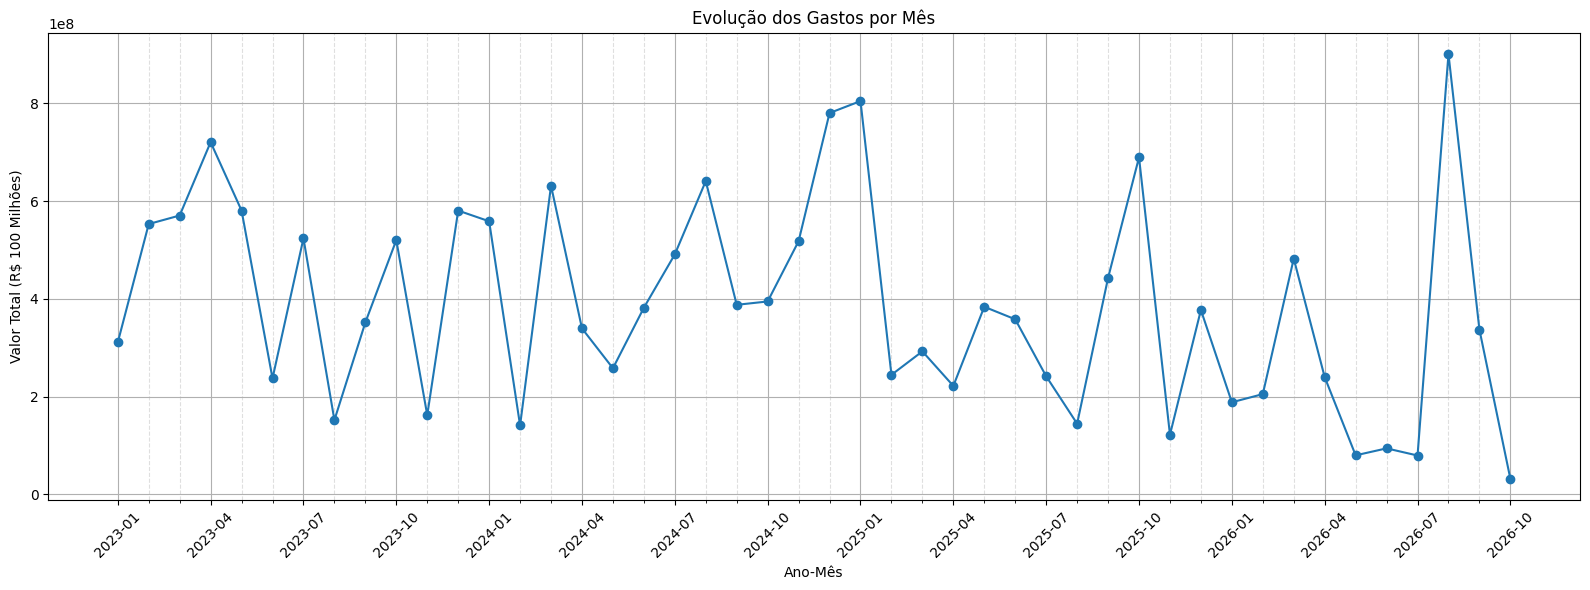

In [10]:
# ---------------------------------------------------
# 1. Garantir processos únicos
# ---------------------------------------------------
processos_unicos = df_limpo.drop_duplicates(subset='Processo')

# ---------------------------------------------------
# 2. Criar coluna Ano-Mês
# ---------------------------------------------------
processos_unicos['AnoMes'] = processos_unicos['DataAprovacao'].dt.to_period('M')

# ---------------------------------------------------
# 3. Agrupar por mês
# ---------------------------------------------------
gastos_mes = (
    processos_unicos
    .groupby('AnoMes')['ValorProcesso']
    .sum()
    .sort_index()
)

# Converter índice para string (melhor para plot)
gastos_mes.index = gastos_mes.index.astype(str)

# ---------------------------------------------------
# 4. Plotar gráfico de linha
# ---------------------------------------------------
plt.figure(figsize=(16,6))

plt.plot(gastos_mes.index, gastos_mes.values, marker='o')

# -------------------------------
# Eixo X
# -------------------------------

# Ticks principais (rótulos a cada 3 meses)
plt.xticks(
    ticks=range(0, len(gastos_mes), 3),
    labels=gastos_mes.index[::3],
    rotation=45
)

# Ticks secundários (todos os meses)
ax = plt.gca()
ax.set_xticks(np.arange(len(gastos_mes)), minor=True)

# -------------------------------
# Grade (grid)
# -------------------------------

# Grade principal (mais forte)
ax.grid(True, which='major', linestyle='-')

# Grade mensal (mais leve)
ax.grid(True, which='minor', linestyle='--', alpha=0.4)

# -------------------------------
# Títulos
# -------------------------------

plt.title('Evolução dos Gastos por Mês')
plt.xlabel('Ano-Mês')
plt.ylabel('Valor Total (R$ 100 Milhões)')

plt.tight_layout()
plt.savefig(
    "/content/evolucao_mes.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

* Histograma e Boxplot

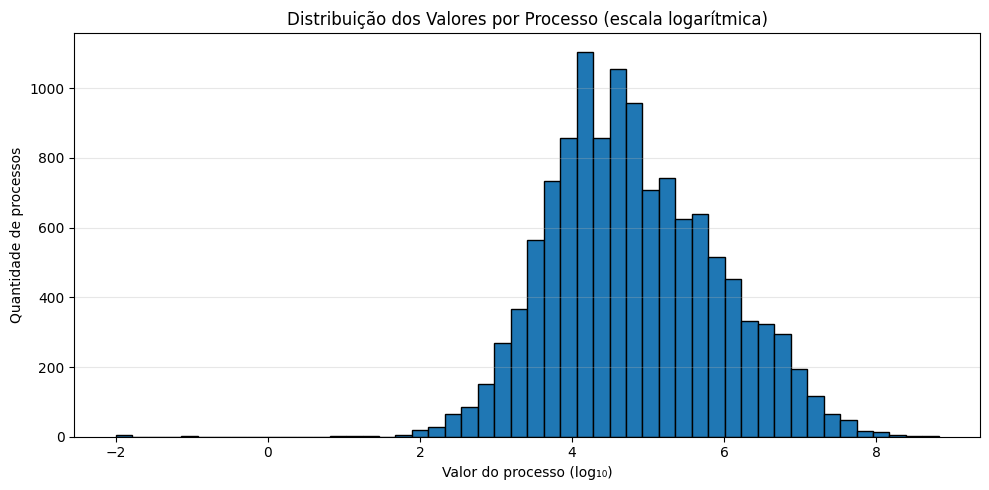

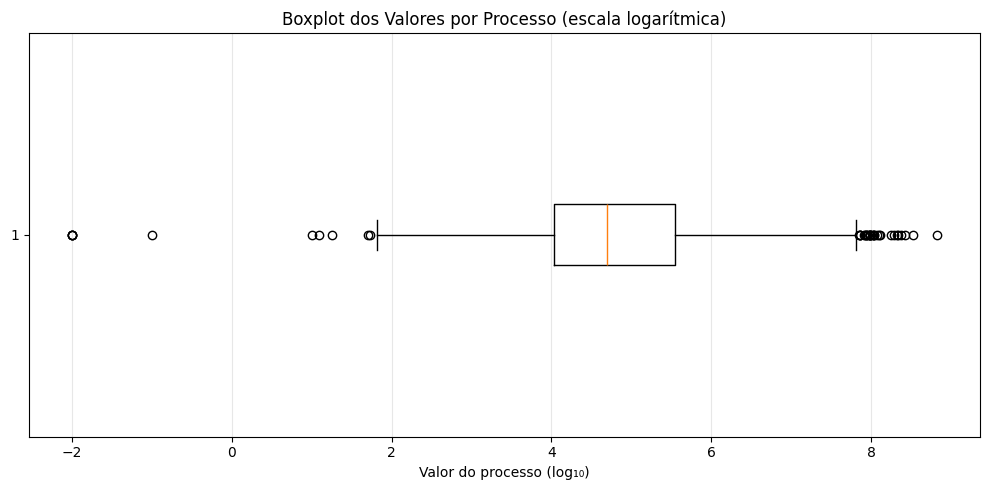

In [11]:
valores = (
    df_limpo[['Processo', 'ValorProcesso']]
    .drop_duplicates(subset='Processo')['ValorProcesso']
)

# Remover valores ausentes e não positivos para a escala logarítmica
valores = valores.dropna()
valores = valores[valores > 0]

#Histograma

plt.figure(figsize=(10, 5))
plt.hist(np.log10(valores), bins=50, edgecolor='black')

plt.title('Distribuição dos Valores por Processo (escala logarítmica)')
plt.xlabel('Valor do processo (log₁₀)')
plt.ylabel('Quantidade de processos')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(
    "/content/hitograma_valor_processo.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Boxplot

plt.figure(figsize=(10, 5))
plt.boxplot(np.log10(valores), vert=False)

plt.title('Boxplot dos Valores por Processo (escala logarítmica)')
plt.xlabel('Valor do processo (log₁₀)')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig(
    "/content/boxplot_valor_processo.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


* Salvar base limpa

In [16]:
display (df_limpo.head())
print(df_limpo.info())

,Processo,ValorProcesso,Objeto,Afastamento,AnoProcesso,DataAprovacao,EnquadramentoLegal,Unidade,FornecedorVencedor,Item,Quantidade,UnidadeMedida,ValorUnitario
0,**SEI-120001/009348/2022,"10,994.00",CONTRATAÇÃO DE PESSOA JURÍDICA ESPECIALIADA EM...,Dispensa - Pequenas Compras,2023,2023-07-05,"De acordo com o artigo24, inciso 2º da Lei Fed...",SEPLAG - Secretaria de Estado de Planejamento ...,MAR E FIRE EQUIP. E PROT. CONTRA INCÊNDIO LTDA-ME,MANUTENCAO EM EXTINTORES DE INCENDIO - DESCRI...,1.00,SERVICO,"10,994.00"
1,020002/000001/2024,936.00,PRESTAÇÃO DE SERVIÇOS DE CARÁTER CONTINUADO CO...,Inexigibilidade - 14.133/2021,2024,2024-02-08,"Lei nº 14.133/2021, Art. 74º, I",EMATER-RIO - EMPR DE ASSIST TÉCN E EXT RURAL D...,ÁGUAS DAS AGULHAS NEGRAS S/A,SERVICO DE FORNECIMENTO DE AGUA - DESCRIÇÃO: C...,12.00,SERVICO,78.00
2,020002/000002/2024,"3,696.00",GERAMOS O PROCESSO ADMINISTRATIVO PARA O EMPEN...,Inexigibilidade - 14.133/2021,2024,2024-02-08,"Lei nº 14.133/2021, Art. 74º, I",EMATER-RIO - EMPR DE ASSIST TÉCN E EXT RURAL D...,AUTARQUIA MUNICIPAL DE ÁGUA E ESGOTO DE CACHOE...,SERVICO DE FORNECIMENTO DE AGUA - DESCRIÇÃO: C...,12.00,SERVICO,308.00
3,020002/000003/2024,"5,040.00",GERAMOS O PROCESSO ADMINISTRATIVO PARA O EMPEN...,Inexigibilidade - 14.133/2021,2024,2024-02-08,"Lei nº 14.133/2021, Art. 74º, I",EMATER-RIO - EMPR DE ASSIST TÉCN E EXT RURAL D...,CONCESSIONÁRIA ÁGUAS DE JUTURNAÍBA S/A,SERVICO DE FORNECIMENTO DE AGUA - DESCRIÇÃO: C...,12.00,SERVICO,420.00
4,020002/000004/2024,"3,120.00",GERAMOS O PROCESSO ADMINISTRATIVO PARA O EMPEN...,Inexigibilidade - 14.133/2021,2024,2024-02-08,"Lei nº 14.133/2021, Art. 74º, I",EMATER-RIO - EMPR DE ASSIST TÉCN E EXT RURAL D...,AGUAS DE NITEROI S/A,SERVICO DE FORNECIMENTO DE AGUA - DESCRIÇÃO: C...,12.00,SERVICO,260.00


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20642 entries, 0 to 20641
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Processo            20642 non-null  object        
 1   ValorProcesso       20642 non-null  float64       
 2   Objeto              20642 non-null  object        
 3   Afastamento         20642 non-null  object        
 4   AnoProcesso         20642 non-null  Int64         
 5   DataAprovacao       20642 non-null  datetime64[ns]
 6   EnquadramentoLegal  20642 non-null  object        
 7   Unidade             20642 non-null  object        
 8   FornecedorVencedor  20642 non-null  object        
 9   Item                20642 non-null  object        
 10  Quantidade          20642 non-null  float64       
 11  UnidadeMedida       20642 non-null  object        
 12  ValorUnitario       20642 non-null  float64       
dtypes: Int64(1), datetime64[ns](1), float64(3), ob

* Salvar base em .csv

In [13]:
# Salvar a base limpa para utilização nas próximas etapas do TCC
arquivo_saida = "/content/df_limpo.csv"

df_limpo.to_csv(
    arquivo_saida,
    index=False,
    encoding="utf-8-sig"
)

print("Base limpa salva com sucesso!")
print(f"Arquivo: {arquivo_saida}")
print(f"Dimensões: {df_limpo.shape[0]} linhas e {df_limpo.shape[1]} colunas")
print(f"Tamanho do arquivo: {__import__('os').path.getsize(arquivo_saida) / 1024:.2f} KB")


Base limpa salva com sucesso!
Arquivo: /content/df_limpo.csv
Dimensões: 20642 linhas e 13 colunas
Tamanho do arquivo: 12343.66 KB


* Salvar base em .parquet

In [15]:
# 1. Definir o caminho de saída para o Parquet
arquivo_saida_parquet = "/content/df_limpo.parquet"

# 3. Salvar a base limpa em Parquet
df_limpo.to_parquet(arquivo_saida_parquet, index=False,)

print("Base limpa salva com sucesso!")
print(f"Arquivo: {arquivo_saida_parquet}")
print(f"Dimensões: {df_limpo.shape[0]} linhas e {df_limpo.shape[1]} colunas")
print(f"Tamanho do arquivo: {__import__('os').path.getsize(arquivo_saida_parquet) / 1024:.2f} KB")



Base limpa salva com sucesso!
Arquivo: /content/df_limpo.parquet
Dimensões: 20642 linhas e 13 colunas
Tamanho do arquivo: 2391.48 KB
